Folie 38: Hausaufgabe

In [3]:
import pandas as pd
forest_fires = pd.read_excel(pd.ExcelFile("C:\\0 Eigene Dateien\\9 Lehre\\2019 Einführung in Data Science\\4. Veranstaltung\\Waldbrände.xlsx"))
forest_fires

,number,year,state,month,number.1,date
0,NaN,Year when Forest Fires happen,Brazilian State,Month when Forest Fires happen,Number of Forest Fires reported,Date when Forest Fires where reported
1,1.0,1998,Acre,Janeiro,0,1998-01-01 00:00:00
2,2.0,1999,Acre,Janeiro,0,1999-01-01 00:00:00
3,3.0,2000,Acre,Janeiro,0,2000-01-01 00:00:00
4,4.0,2001,Acre,Janeiro,0,2001-01-01 00:00:00
...,...,...,...,...,...,...
393,393.0,2010,Alagoas,Agosto,1,2010-01-01 00:00:00
394,394.0,2011,Alagoas,Agosto,4,2011-01-01 00:00:00
395,395.0,2012,Alagoas,Agosto,0,2012-01-01 00:00:00
396,396.0,2013,Alagoas,Agosto,0,2013-01-01 00:00:00


In [4]:
forest_fires_filtered=forest_fires.drop([0], axis=0)
forest_fires_filtered.replace(["Janeiro", "Fevereiro", "Março", "Abril","Maio","Junho", "Julho","Agosto","Setembro","Outubro","Novembro","Dezembro"], [1, 2, 3,4,5,6,7,8,9,10,11,12], inplace = True)
forest_fires_filtered.rename(columns={"number.1": "absolute"}, inplace = True)
forest_fires_grouped = forest_fires_filtered.groupby(["state","month"], as_index = False).sum()
forest_fires_grouped["absolute"]=(forest_fires_grouped["absolute"]/forest_fires_grouped["absolute"].sum())
forest_fires_probs=pd.DataFrame(forest_fires_grouped[["state","month","absolute"]])
import seaborn as sns
cm = sns.diverging_palette(120, 10, as_cmap=True)
s = forest_fires_probs.style.background_gradient(cmap=cm)
s

,state,month,absolute
0,Acre,1,0.000234
1,Acre,2,0.000111
2,Acre,3,0.000135
3,Acre,4,0.000240
4,Acre,5,0.000474
5,Acre,6,0.001504
6,Acre,7,0.013432
7,Acre,8,0.367270
8,Acre,9,0.547211
9,Acre,10,0.051207


Folie 42

In [1]:
import pandas as pd
df = pd.read_csv("C:\\0 Eigene Dateien\\9 Lehre\\2019 Einführung in Data Science\\5. Veranstaltung\\temperatures.csv",
                 sep=";",
                 index_col=0,
                 decimal=".")
df

,sensor1,sensor2,sensor3,sensor4,sensor5,sensor6
time,,,,,,
06:00:00,14.3,13.7,14.2,14.3,13.5,13.6
06:15:00,14.5,14.5,14.0,15.0,14.5,14.7
06:30:00,14.6,15.1,14.8,15.3,14.0,14.2
06:45:00,14.8,14.5,15.6,15.2,14.7,14.6
07:00:00,15.0,14.9,15.7,15.6,14.0,15.3


In [7]:
df["sensor1"]

time
06:00:00    14.3
06:15:00    14.5
06:30:00    14.6
06:45:00    14.8
07:00:00    15.0
Name: sensor1, dtype: float64

In [8]:
df2 = df.mean(axis = 0)
df2

sensor1     14.64
sensor2     14.54
sensor3     14.86
sensor4     15.08
sensor5     14.14
sensor6     14.48
dtype: float64

In [9]:
df.describe()

,sensor1,sensor2,sensor3,sensor4,sensor5,sensor6
count,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000
mean,14.640000,14.540000,14.860000,15.080000,14.140000,14.480000
std,0.270185,0.536656,0.779744,0.486826,0.472229,0.630079
min,14.300000,13.700000,14.000000,14.300000,13.500000,13.600000
25%,14.500000,14.500000,14.200000,15.000000,14.000000,14.200000
50%,14.600000,14.500000,14.800000,15.200000,14.000000,14.600000
75%,14.800000,14.900000,15.600000,15.300000,14.500000,14.700000
max,15.000000,15.100000,15.700000,15.600000,14.700000,15.300000


In [2]:
import numpy as np
random_df = pd.DataFrame(np.random.random(size=(5, 6)), 
                         columns=df.columns.values, 
                         index=df.index)
nan_df = pd.DataFrame(np.nan,
                      columns=df.columns.values, 
                      index=df.index)
df_bool = random_df<0.8
df_with_nan = df.where(df_bool, nan_df)
#Alternative: df_with_nan = df.where(df_bool, np.nan)
df_with_nan

,sensor1,sensor2,sensor3,sensor4,sensor5,sensor6
time,,,,,,
06:00:00,14.3,NaN,NaN,14.3,NaN,13.6
06:15:00,14.5,14.5,14.0,NaN,14.5,14.7
06:30:00,14.6,15.1,14.8,15.3,14.0,14.2
06:45:00,14.8,14.5,NaN,15.2,NaN,14.6
07:00:00,15.0,14.9,15.7,15.6,14.0,15.3


Folie 43

In [3]:
df_no_nan = df_with_nan.dropna()
df_no_nan

,sensor1,sensor2,sensor3,sensor4,sensor5,sensor6
time,,,,,,
06:30:00,14.6,15.1,14.8,15.3,14.0,14.2
07:00:00,15.0,14.9,15.7,15.6,14.0,15.3


In [4]:
df_no_nan = df_with_nan.dropna(axis = 1)
df_no_nan

,sensor1,sensor6
time,,
06:00:00,14.3,13.6
06:15:00,14.5,14.7
06:30:00,14.6,14.2
06:45:00,14.8,14.6
07:00:00,15.0,15.3


In [22]:
df_no_nan = df_with_nan.dropna(thresh = 4, axis = 1)
df_no_nan

,sensor1,sensor2,sensor3,sensor4,sensor5
time,,,,,
06:00:00,14.3,13.7,NaN,14.3,13.5
06:15:00,14.5,14.5,14.0,15.0,14.5
06:30:00,14.6,15.1,14.8,15.3,14.0
06:45:00,14.8,NaN,15.6,NaN,14.7
07:00:00,NaN,14.9,15.7,15.6,NaN


In [24]:
df_with_nan.dropna(thresh = 4).mean()

sensor1     14.550
sensor2     14.550
sensor3     15.025
sensor4     15.050
sensor5     14.175
sensor6     14.500
dtype: float64

Folie 44

In [25]:
import pandas as pd
cities = ["Vienna", "Vienna", "Vienna",
          "Hamburg", "Hamburg", "Hamburg",
          "Berlin", "Berlin", "Berlin",
          "Zürich", "Zürich", "Zürich"]
index = [cities, ["country", "area", "population",
                  "country", "area", "population",
                  "country", "area", "population",
                  "country", "area", "population"]]
data = ["Austria", 414.60,    1805681,
        "Germany", 755.00,    1760433,
        "Germany", 891.85,    3562166,
        "Switzerland", 87.88, 378884]
city_series = pd.Series(data, index=index)
print(city_series)

Vienna   country           Austria
         area                414.6
         population        1805681
Hamburg  country           Germany
         area                755.0
         population        1760433
Berlin   country           Germany
         area               891.85
         population        3562166
Zürich   country       Switzerland
         area                87.88
         population         378884
dtype: object


Folie 46

In [28]:
city_series["Vienna", "area"]

414.6

In [29]:
city_series = city_series.sort_index()
city_series["Berlin":"Vienna"]

Berlin   area           891.85
         country       Germany
         population    3562166
Hamburg  area            755.0
         country       Germany
         population    1760433
Vienna   area            414.6
         country       Austria
         population    1805681
dtype: object

In [30]:
city_series[["Vienna","Hamburg"]]

Vienna   area            414.6
         country       Austria
         population    1805681
Hamburg  area            755.0
         country       Germany
         population    1760433
dtype: object

In [31]:
city_series[:, "area"]

Berlin     891.85
Hamburg     755.0
Vienna      414.6
Zürich      87.88
dtype: object

In [32]:
for i in range(len(city_series.index.levels)):
      print(city_series.index.levels[i]) 

Index(['Berlin', 'Hamburg', 'Vienna', 'Zürich'], dtype='object')
Index(['area', 'country', 'population'], dtype='object')


Folie 47

In [27]:
city_series.unstack()

,area,country,population
Berlin,891.85,Germany,3562166
Hamburg,755.0,Germany,1760433
Vienna,414.6,Austria,1805681
Zürich,87.88,Switzerland,378884


Folie 48: Mehrfachindizierung

In [33]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

cnt_times = 24
cnt_machines = 5

curr_time = datetime.now()

machines = ["Maschine " + str(i) for  i in range(1, cnt_machines) for j in range(cnt_times)]
times = [curr_time+ timedelta(0,j*60) for i in range(len(machines)) for j in range(cnt_times)]

labels = list(zip(machines, times))
values = np.random.random(cnt_times*cnt_machines)
index = dict(zip(labels, values))
series = pd.Series(index)
series.unstack()

,2023-01-02 11:09:46.700058,2023-01-02 11:10:46.700058,2023-01-02 11:11:46.700058,2023-01-02 11:12:46.700058,2023-01-02 11:13:46.700058,2023-01-02 11:14:46.700058,2023-01-02 11:15:46.700058,2023-01-02 11:16:46.700058,2023-01-02 11:17:46.700058,2023-01-02 11:18:46.700058,...,2023-01-02 11:23:46.700058,2023-01-02 11:24:46.700058,2023-01-02 11:25:46.700058,2023-01-02 11:26:46.700058,2023-01-02 11:27:46.700058,2023-01-02 11:28:46.700058,2023-01-02 11:29:46.700058,2023-01-02 11:30:46.700058,2023-01-02 11:31:46.700058,2023-01-02 11:32:46.700058
Maschine 1,0.543595,0.732370,0.877946,0.009516,0.607655,0.241586,0.314384,0.369565,0.475091,0.420005,...,0.080104,0.282842,0.734440,0.866037,0.106807,0.719896,0.812767,0.293415,0.335846,0.060271
Maschine 2,0.166246,0.056186,0.510468,0.242415,0.296269,0.306733,0.607662,0.206718,0.222963,0.582637,...,0.421708,0.546147,0.217488,0.724451,0.776604,0.945946,0.278082,0.266154,0.247832,0.971837
Maschine 3,0.396845,0.553207,0.315405,0.605122,0.021833,0.083030,0.652929,0.078196,0.241775,0.707134,...,0.138203,0.038749,0.683653,0.220237,0.382748,0.618519,0.245576,0.232773,0.523327,0.793931
Maschine 4,0.491847,0.239788,0.655196,0.167965,0.600627,0.665929,0.931029,0.581146,0.666272,0.695164,...,0.353872,0.525883,0.780500,0.487783,0.035141,0.562306,0.406511,0.388588,0.893143,0.768446


Folie 50: Binning

In [34]:
def create_bins(lower_bound, width, quantity):
    bins = []
    for low in range(lower_bound, 
                     lower_bound + quantity * width + 1, width):
        bins.append((low, low+width))
    return bins

def find_bin(value, bins):
    for i in range(0, len(bins)):
        if bins[i][0] <= value < bins[i][1]:
            return i
    return -1

In [35]:
# Alternative
def create_bins(lower_bound, width, quantity):
    bins = [(low, low+width) for low in range(lower_bound, 
                     lower_bound + quantity * width + 1, width)]
    return bins

def find_bin(value, bins):
    for i in range(0, len(bins)):
        if bins[i][0] < value <= bins[i][1]:
            return i
    return -1

In [36]:
from collections import Counter
bins = create_bins(lower_bound=50,
                   width=4,
                   quantity=10)
print(bins)
weights_of_persons = [50.51, 69.3, 64.9, 75.6, 74.9, 80.3, 
                      78.6, 84.1, 88.9, 90.3, 83.4, 69.3, 
                      52.4, 58.3, 67.4, 74.0, 89.3, 100]
binned_weights = []
for value in weights_of_persons:
    bin_index = find_bin(value, bins)
    print(value, bin_index, bins[bin_index])
    binned_weights.append(bins[bin_index])
    
frequencies = Counter(binned_weights)
print(frequencies)

[(50, 54), (54, 58), (58, 62), (62, 66), (66, 70), (70, 74), (74, 78), (78, 82), (82, 86), (86, 90), (90, 94)]
50.51 0 (50, 54)
69.3 4 (66, 70)
64.9 3 (62, 66)
75.6 6 (74, 78)
74.9 6 (74, 78)
80.3 7 (78, 82)
78.6 7 (78, 82)
84.1 8 (82, 86)
88.9 9 (86, 90)
90.3 10 (90, 94)
83.4 8 (82, 86)
69.3 4 (66, 70)
52.4 0 (50, 54)
58.3 2 (58, 62)
67.4 4 (66, 70)
74.0 5 (70, 74)
89.3 9 (86, 90)
100 -1 (90, 94)
Counter({(66, 70): 3, (50, 54): 2, (74, 78): 2, (78, 82): 2, (82, 86): 2, (86, 90): 2, (90, 94): 2, (62, 66): 1, (58, 62): 1, (70, 74): 1})


Folie 53

In [37]:
a = pd.IntervalIndex.from_tuples(bins)
a

IntervalIndex([(50, 54], (54, 58], (58, 62], (62, 66], (66, 70] ... (74, 78], (78, 82], (82, 86], (86, 90], (90, 94]], dtype='interval[int64, right]')

In [38]:
bins = np.linspace(50, 100, 11)
print(bins)
categorial_object = pd.cut(weights_of_persons, bins)
#categorial_object = pd.cut(weights_of_persons, bins = 11, include_lowest = True)

[ 50.  55.  60.  65.  70.  75.  80.  85.  90.  95. 100.]


In [39]:
categorial_object = pd.cut(weights_of_persons, 5)
categorial_object

[(50.461, 60.408], (60.408, 70.306], (60.408, 70.306], (70.306, 80.204], (70.306, 80.204], ..., (50.461, 60.408], (60.408, 70.306], (70.306, 80.204], (80.204, 90.102], (90.102, 100.0]]
Length: 18
Categories (5, interval[float64, right]): [(50.461, 60.408] < (60.408, 70.306] < (70.306, 80.204] < (80.204, 90.102] < (90.102, 100.0]]

In [40]:
categorial_object = pd.cut(weights_of_persons, [50,60,75,80,85,90,100])
categorial_object

[(50, 60], (60, 75], (60, 75], (75, 80], (60, 75], ..., (50, 60], (60, 75], (60, 75], (85, 90], (90, 100]]
Length: 18
Categories (6, interval[int64, right]): [(50, 60] < (60, 75] < (75, 80] < (80, 85] < (85, 90] < (90, 100]]

In [41]:
pd.value_counts(categorial_object)

(60, 75]     6
(50, 60]     3
(80, 85]     3
(75, 80]     2
(85, 90]     2
(90, 100]    2
dtype: int64

In [42]:
categorial_object.codes

array([0, 1, 1, 2, 1, 3, 2, 3, 4, 5, 3, 1, 0, 0, 1, 1, 4, 5], dtype=int8)

In [43]:
categorial_object.categories

IntervalIndex([(50, 60], (60, 75], (75, 80], (80, 85], (85, 90], (90, 100]], dtype='interval[int64, right]')

Folie 54: Binning mit Pandas

In [44]:
degrees = ["non rite", 
           "rite", 
           "cum laude", 
           "magna cum laude", 
           "summa cum laude"][::-1]
intervals = [6.0, 4.01, 3.0, 2.0, 1.0, 0.66][::-1]
student_results = [1.00, 0.75, 1.5, 
                   2.66, 4.0, 1.3, 
                   2.7, 3.8, 2.2, 
                   1.2, 1.6]
student_results_degrees, bins = pd.cut(student_results,
                                 intervals,
                                 labels=degrees,
                                 right=True,
                                 retbins=True)
print(pd.value_counts(student_results_degrees))
print(student_results_degrees.categories)
print(bins)
#student_results_degrees.categories = degrees

magna cum laude    4
cum laude          3
summa cum laude    2
rite               2
non rite           0
dtype: int64
Index(['summa cum laude', 'magna cum laude', 'cum laude', 'rite', 'non rite'], dtype='object')
[0.66 1.   2.   3.   4.01 6.  ]


<AxesSubplot:>

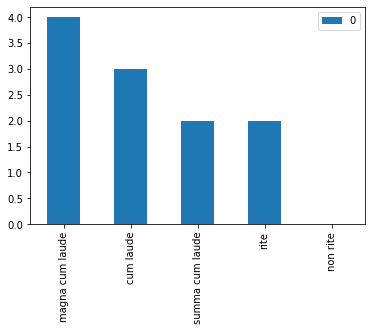

In [45]:
pd.DataFrame(pd.value_counts(student_results_degrees)).plot.bar()

<AxesSubplot:ylabel='Frequency'>

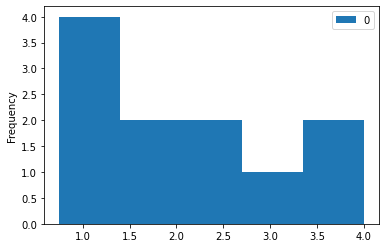

In [46]:
df = pd.DataFrame(student_results)
df.plot.hist(bins=5)

Folie 56

In [47]:
from datetime import date
date.max

datetime.date(9999, 12, 31)

In [48]:
date.min

datetime.date(1, 1, 1)

In [49]:
x = date(1984, 3, 31)
x

datetime.date(1984, 3, 31)

In [50]:
date.max.toordinal()

3652059

In [51]:
date.today().toordinal()

738522

In [52]:
date.today().month

1

In [53]:
date.today().weekday()

0

Folie 57

In [54]:
from datetime import time
time.min

datetime.time(0, 0)

In [55]:
time.max

datetime.time(23, 59, 59, 999999)

In [56]:
y = time(16,46,59)
y

datetime.time(16, 46, 59)

In [58]:
print(y.hour)
print(y.minute)
print(y.second)

16
46
59


In [59]:
y.replace(hour = 11, minute  =32)

datetime.time(11, 32, 59)

Folie 58

In [60]:
from datetime import datetime
z = datetime(2019,11,12,16,59,22)

In [61]:
print(z.tzinfo)

None


In [62]:
z.tzinfo != None and z.tzinfo.utcoffset(z) != None

False

In [63]:
from datetime import datetime
import pytz
t = datetime.now(pytz.utc)

In [64]:
t.tzinfo

<UTC>

In [65]:
t.tzinfo.utcoffset(t)

datetime.timedelta(0)

Folie 59

In [66]:
from datetime import datetime
delta = datetime(1993, 12, 14) - datetime(1991, 4, 30)
print(delta, type(delta))

959 days, 0:00:00 <class 'datetime.timedelta'>


In [67]:
delta.total_seconds()

82857600.0

In [68]:
delta.days

959

In [69]:
delta.seconds

0

In [70]:
from datetime import datetime, timedelta
d1 = datetime(1991, 4, 30)
d2 = d1 + timedelta(10)
print(d2)
print(d2 - d1)
d3 = d1 - timedelta(100)
print(d3)
d4 = d1 - 2 * timedelta(50)
print(d4)
d5 = d1 + timedelta(10,100)
print(d5)

1991-05-10 00:00:00
10 days, 0:00:00
1991-01-20 00:00:00
1991-01-20 00:00:00
1991-05-10 00:01:40


Folie 60

In [71]:
print(d1.strftime('%Y-%m-%d'))
print("Wochentag: " + d1.strftime('%a'))
print("Wochentag ausgeschrieben: " + d1.strftime('%A'))
# Weekday as a decimal number, where 0 is Sunday 
# and 6 is Saturday
print("Wochentag als Dezimalzahl: " + d1.strftime('%w'))

1991-04-30
Wochentag: Tue
Wochentag ausgeschrieben: Tuesday
Wochentag als Dezimalzahl: 2


In [72]:
from datetime import datetime, timedelta
import locale
# Umstellung auf Deutsch:
locale.setlocale(locale.LC_ALL, 'german')
d1 = datetime(1993, 12, 14)
print(d1.strftime('%d. %B %Y'))
print("Nur in Zahlen:")
print(d1.strftime('%d.%m.%Y'))
print(f"Der {d1.strftime('%d.%m.%Y'):s} war ein {d1.strftime('%A'):s}!")

14. Dezember 1993
Nur in Zahlen:
14.12.1993
Der 14.12.1993 war ein Dienstag!


In [74]:
from dateutil.parser import parse
print(parse('2011-01-03'))
print(parse('Wed Apr 12 20:29:53 2017'))

2011-01-03 00:00:00
2017-04-12 20:29:53


Folie 61: Datetime

In [85]:
from dateutil.parser import parse
from datetime import datetime, timedelta

def passed_since_conquista(date_time):
    if type(date_time) == str:
        cur_date = parse(date_time)
    else:
        cur_date = date_time
    dif = cur_date - parse("1492-10-12")
    print(dif.days)
passed_since_conquista(datetime.combine(date.today(), datetime.min.time()))

193660


Folie 62

In [86]:
import pandas as pd
from datetime import datetime, timedelta as delta
ndays = 10
start = datetime(2018, 12, 1)
dates = [start + delta(days = x) for x in range(0, ndays)]
values = [25, 50, 15, 67, 70, 9, 28, 30, 32, 12]
ts = pd.Series(values, index = dates)
print(ts)

2018-12-01    25
2018-12-02    50
2018-12-03    15
2018-12-04    67
2018-12-05    70
2018-12-06     9
2018-12-07    28
2018-12-08    30
2018-12-09    32
2018-12-10    12
dtype: int64


Folie 63

In [87]:
ts3 = pd.Series(values, index = pd.date_range(start, periods = ndays, freq = "D"))
ts3

2018-12-01    25
2018-12-02    50
2018-12-03    15
2018-12-04    67
2018-12-05    70
2018-12-06     9
2018-12-07    28
2018-12-08    30
2018-12-09    32
2018-12-10    12
Freq: D, dtype: int64

Folie 65

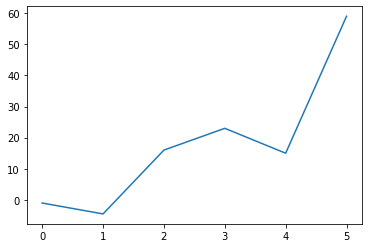

In [88]:
import matplotlib.pyplot as plt
plt.plot([-1, -4.5, 16, 23, 15, 59])
plt.show()

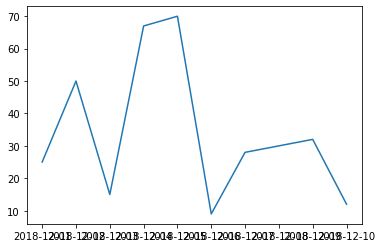

In [89]:
from pandas.plotting import register_matplotlib_converters
register_matplotlib_converters()
plt.plot(ts)

<AxesSubplot:>

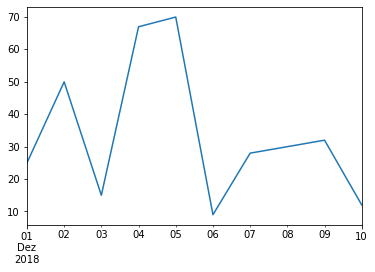

In [90]:
ts.plot()

Folie 67:Plotten einer Zeitreihe

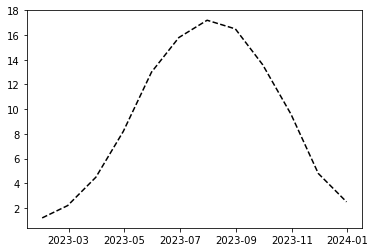

In [91]:
from datetime import datetime, timedelta as delta, date
temp = [1.2 ,2.2, 4.5, 8.2, 13, 15.8, 17.2, 16.5, 13.6, 9.6, 4.8, 2.5]
index = pd.date_range(date(datetime.now().year,1,1), date(datetime.now().year,12,31), freq="M")
temp_series = pd.Series(temp, index = index)
plt.plot(temp_series, "--k")

Folie 68

[0, 3, 6, 9, 12, 15, 18, 21]


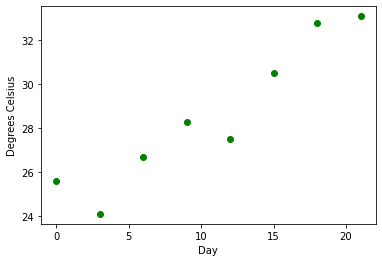

In [92]:
# die X-Werte:
days = list(range(0, 22, 3))
print(days)
# die Y-Werte:
celsius_values = [25.6, 24.1, 26.7, 28.3, 27.5, 30.5, 32.8, 33.1]
plt.plot(days, celsius_values, "og")
plt.xlabel('Day')
plt.ylabel('Degrees Celsius')
plt.show()

Folie 70: Plotten einer Funktion

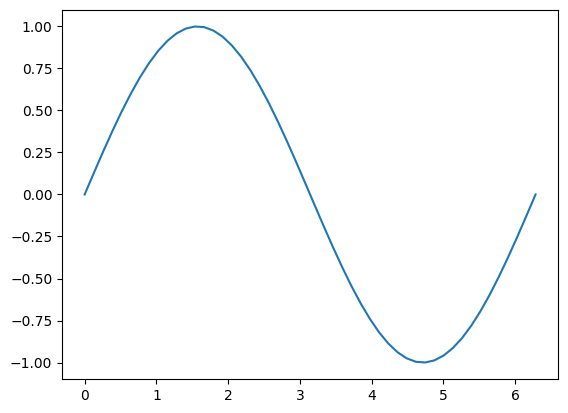

In [6]:
import numpy as np
import matplotlib.pyplot as plt
X = np.linspace(0, 2 * np.pi, 50, endpoint=True)
F = np.sin(X)
plt.plot(X,F)
plt.show()

Folie 71: Plotten einer Funktion

4.389273405075073


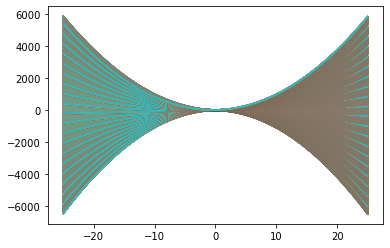

In [94]:
import time
start =time.time()
X = np.linspace(-25, 25, 50, endpoint=True)
r = 10
functions = ((a*X**2+b*X+c) for a in range(-r,r) for b in range(-r,r) for c in range(-r,r) )
for f in functions:
    plt.plot(X,f)
end =time.time()
print(end-start)

3.2011656761169434


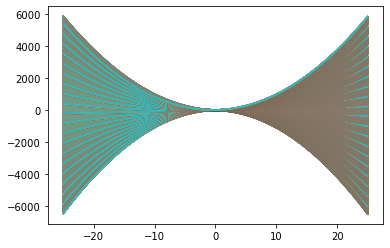

In [95]:
import time
start =time.time()
X = np.linspace(-25, 25, 50, endpoint=True)
r = 10
functions = np.array([(a*X**2+b*X+c) for a in range(-r,r) for b in range(-r,r) for c in range(-r,r)])
X = np.tile(X,(int(((r*2)**3)),1))

plt.plot(X.T,functions.T)
end =time.time()
print(end-start)

3.139180898666382


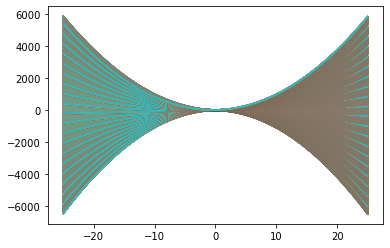

In [96]:
start =time.time()
X = np.linspace(-25, 25, 50, endpoint=True)
r = 10
A,B,C = np.meshgrid(range(-r,r),range(-r,r),range(-r,r), indexing="ij")
A = np.reshape(A,(r*2)**3)
B = np.reshape(B,(r*2)**3)
C = np.reshape(C,(r*2)**3)

X=X.reshape(X.shape[0],1)

Y=A*X**2+B*X+C
plt.plot(X,Y)
end =time.time()
print(end-start)

4.654433250427246


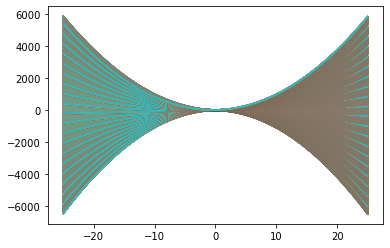

In [97]:
start =time.time()
def poly_gen(a=1, b=1, c=1):
    def polynom(x):
        return a*x**2+b*x+c
    return polynom
X = np.linspace(-25, 25, 50, endpoint=True)
r = 10
weights = ((a,b,c) for a in range(-r,r) for b in range(-r,r) for c in range(-r,r) )
for a,b,c in weights:
    F = poly_gen(a,b,c)(X)
    plt.plot(X,F)
end =time.time()
print(end-start)

Folie 72

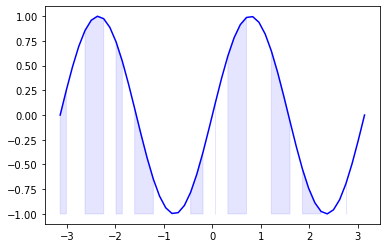

array([1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0,
       0, 0, 1, 0, 0, 0])

In [98]:
n=50
where_list = np.random.choice([0,1],50)
X = np.linspace(-np.pi,np.pi,n,endpoint=True)
Y = np.sin(2*X)
plt.plot (X, Y, color='blue', alpha=1.00)
plt.fill_between(X, -1, Y, color='blue', alpha=.1, where=where_list)
plt.show()
where_list

Folie 73: Bereiche einfärben

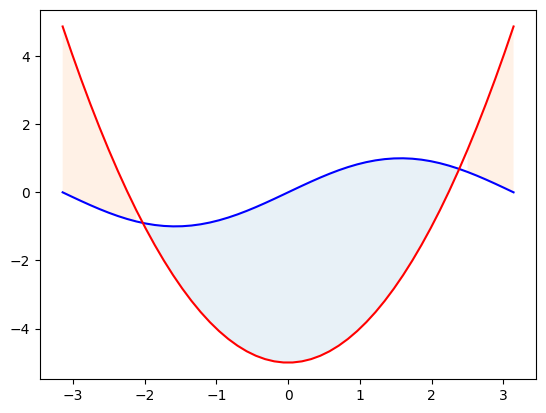

In [11]:
X = np.linspace(-np.pi,np.pi,50)
F1 = np.sin(X)
F2 = (lambda x: x**2-5)(X)
plt.plot(X, F1, "-b")
plt.plot(X, F2, "-r")
plt.fill_between(X,F1,F2, where=F1>=F2, alpha = .1)
plt.fill_between(X,F1,F2, where=F1<F2, alpha = .1)

Folie 74

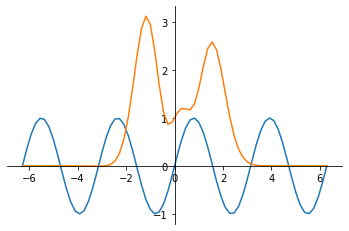

In [100]:
X  = np.linspace(-2 * np.pi, 2 * np.pi, 70, endpoint=True)
F1 = np.sin(2* X)
F2 = (2*X**5 + 4*X**4 - 4.8*X**3 + 1.2*X**2 + X + 1)*np.exp(-X**2)
# aktuellen Plot zuweisen:
ax = plt.gca()
# Obere und rechte Achse unsichtbar werden lassen:
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
# Untere Achse auf die y=0 Position bewegen:
ax.xaxis.set_ticks_position('bottom')
ax.spines['bottom'].set_position(('data',0))
# Linke Achse auf die Position x == 0 bewegen:
ax.yaxis.set_ticks_position('left')
ax.spines['left'].set_position(('data',0))
plt.plot(X, F1)
plt.plot(X, F2)
plt.show()

Folie 76: Graphen individualisieren

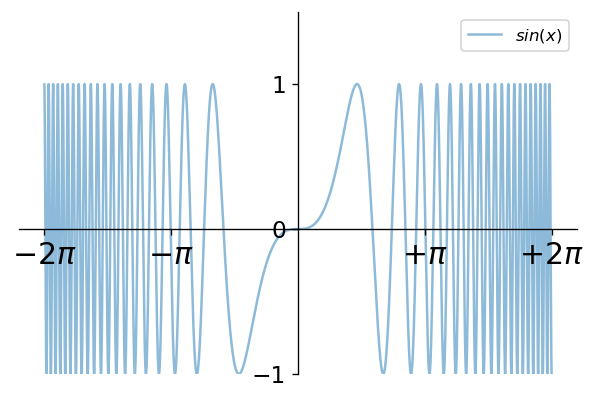

In [101]:
plt.figure(dpi= 120)
plt.rcParams["axes.axisbelow"] = False
X = np.linspace(-2 * np.pi, 2 * np.pi, 10000, endpoint=True)
F1 = np.sin(X**3 / 2)
ax = plt.gca()
ax.spines['top'].set_color('none')
ax.spines['right'].set_color('none')
ax.xaxis.set_ticks_position('bottom')
ax.spines['bottom'].set_position(('data',0))
ax.yaxis.set_ticks_position('left')
ax.spines['left'].set_position(('data',0))
plt.xticks( [-2*np.pi, -np.pi, np.pi, 2*np.pi],
        [r'$-2\pi$', r'$-\pi$', r'$+\pi$', r'$+2\pi$'])
plt.yticks([-3, -1, 0, +1, 3])
for xtick in ax.get_xticklabels():
    xtick.set_fontsize(18)
for ytick in ax.get_yticklabels():
    ytick.set_fontsize(14)
plt.plot(X, F1, label="$sin(x)$", alpha = .5)
plt.ylim(-1,1.5)
plt.legend(loc ="upper right")

Folie 77

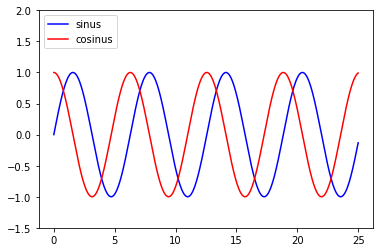

In [102]:
x = np.linspace(0, 25, 1000)
y1 = np.sin(x)
y2 = np.cos(x)
plt.plot(x, y1, '-b', label='sinus')
plt.plot(x, y2, '-r', label='cosinus')
plt.legend(loc='upper left')
plt.ylim(-1.5, 2.0)
plt.show()

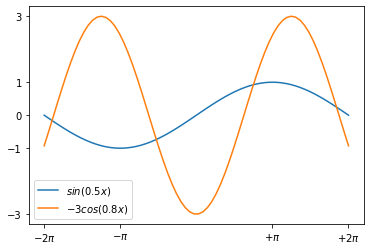

In [103]:
X = np.linspace(-2 * np.pi, 2 * np.pi, 70, endpoint=True)
F1 = np.sin(0.5*X)
F2 = -3 * np.cos(0.8*X)
plt.xticks( [-6.28, -3.14, 3.14, 6.28],
        [r'$-2\pi$', r'$-\pi$', r'$+\pi$', r'$+2\pi$'])
plt.yticks([-3, -1, 0, +1, 3])
plt.plot(X, F1, label="$sin(0.5x)$")
plt.plot(X, F2, label="$-3 cos(0.8x)$")
plt.legend(loc='best')
plt.show()

Folie 78

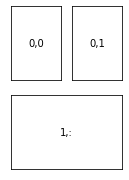

In [104]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(2, 3))
gs = GridSpec(2,2)
a1 = fig.add_subplot(gs[0,0])
a1.set_xticks([])
a1.set_yticks([])
a1.text(0.5,0.5, "0,0", ha = "center", va = "center")
a2 = fig.add_subplot(gs[0,1])
a2.set_xticks([])
a2.set_yticks([])
a2.text(0.5,0.5, "0,1", ha = "center", va = "center")
a3 = fig.add_subplot(gs[1,:])
a3.set_xticks([])
a3.set_yticks([])
a3.text(0.5,0.5, "1,:", ha = "center", va = "center")
plt.show()

Folie 79: Mehrfache Plots

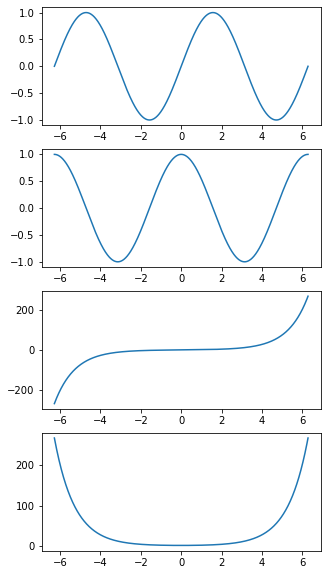

In [106]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
X = np.linspace(-2*np.pi,2*np.pi,1000)
F1 = np.sin(X)
F2 = np.cos(X)
F3 = np.sinh(X)
F4 = np.cosh(X)
fig = plt.figure(figsize=(5, 10))
gs = GridSpec(4,1)
a1 = fig.add_subplot(gs[0,0])
a1.plot(X, F1)
a2 = fig.add_subplot(gs[1,0])
a2.plot(X, F2)
a3 = fig.add_subplot(gs[2,0])
a3.plot(X, F3)
a4 = fig.add_subplot(gs[3,0])
a4.plot(X, F4)
plt.show()

Folie 80

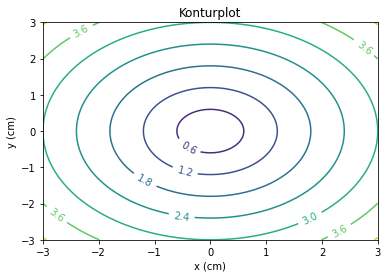

In [107]:
import numpy as np
import matplotlib.pyplot as plt
xlist = np.linspace(-3.0, 3.0, 100)
ylist = np.linspace(-3.0, 3.0, 100)
X, Y = np.meshgrid(xlist, ylist)
Z = np.sqrt(X**2 + Y**2)
cp = plt.contour(X, Y, Z)
plt.clabel(cp, inline=True, 
          fontsize=10)
plt.title('Konturplot')
plt.xlabel('x (cm)')
plt.ylabel('y (cm)')
plt.show()

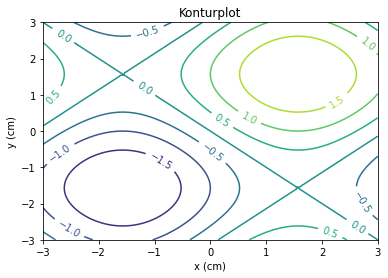

In [108]:
import numpy as np
import matplotlib.pyplot as plt
xlist = np.linspace(3.0, -3.0, 100)
ylist = np.linspace(3.0, -3.0, 100)
X, Y = np.meshgrid(xlist, ylist)
Z = (np.sin(X)+np.sin(Y))
cp = plt.contour(X, Y, Z)
plt.clabel(cp, inline=True, 
          fontsize=10)
plt.title('Konturplot')
plt.xlabel('x (cm)')
plt.ylabel('y (cm)')
plt.show()

Folie 81

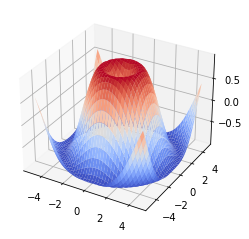

In [114]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np

ax = plt.axes(projection='3d')

X = np.arange(-5, 5, 0.25)
Y = np.arange(-5, 5, 0.25)
X, Y = np.meshgrid(X, Y)
R = np.sqrt(X**2 + Y**2)
Z = np.sin(R)

# Plot the surface.
surf = ax.plot_surface(X, Y, Z, cmap=cm.coolwarm)

plt.show()

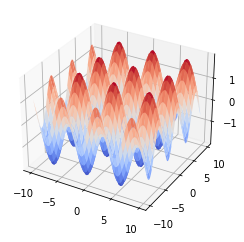

In [113]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
from matplotlib import cm
import numpy as np

ax = plt.axes(projection='3d')

X = np.arange(-10, 10, 0.25)
Y = np.arange(-10, 10, 0.25)
X, Y = np.meshgrid(X, Y)
Z = (np.sin(X)+np.sin(Y))
# Plot the surface.
surf = ax.plot_surface(X, Y, Z, cmap=cm.coolwarm)

plt.show()